<div style="background:#174D75;color:#F8F5E4;padding:18px 22px;border-radius:4px">
<h1 style="margin:0;font-family:Montserrat,Arial,sans-serif;letter-spacing:1px">HOOPMIND · ¿QUÉ FORMA TIENE EL DATASET?</h1>
<p style="margin:6px 0 0 0">Big Data + IA · NBA, solo datos de equipo y partido (sin jugadores)</p>
</div>

**Para qué sirve este notebook.** Enseñar, paso a paso y con datos reales, cómo pasamos de los CSV en bruto
(`Games.csv`, `TeamStatistics.csv`) a **la tabla final que verá el modelo**: *una fila por partido*, con unas
columnas de entrada (X) y dos columnas de salida (y).

Los pasos son:
1. Cargar y mirar las tablas en bruto.
2. Poner cada partido «desde el punto de vista de cada equipo».
3. Calcular el resumen de los **últimos partidos de cada equipo, usando solo partidos anteriores** (sin hacer trampas).
4. Pegar local y visitante en **una sola fila por partido**.
5. Mostrar el dataset final, qué es entrada y qué es salida, y cómo lo separamos por fechas.

> **Todavía no elegimos modelo** (todavía no lo sabemos). Aquí solo se prepara la tabla; el modelo viene después.

In [1]:
import os, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paleta HoopMind (docs/PALETA_HOOPMIND.md)
CREMA, AZUL, GRANATE = "#F8F5E4", "#174D75", "#21060A"
AZUL_CLARO, GRANATE_CLARO = "#DCE7EF", "#E8D9DC"
plt.rcParams.update({"figure.facecolor": CREMA, "axes.facecolor": CREMA, "axes.edgecolor": GRANATE,
                     "axes.labelcolor": GRANATE, "text.color": GRANATE, "xtick.color": GRANATE,
                     "ytick.color": GRANATE, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

# Dónde están los CSV (en HDFS están en /nba/raw/fecha=2026-11-17; aquí usamos la copia local).
# Los CSV NO se suben a GitHub: cada persona los baja con scripts/ingest_raw.sh o con la CLI de Kaggle.
candidatos = [os.environ.get("NBA_DATOS", ""), str(pathlib.Path.home() / "nba-datos"), "data", "../data"]
RUTA = next(pathlib.Path(c) for c in candidatos if c and (pathlib.Path(c) / "Games.csv").exists())
print("Datos en:", RUTA.resolve())

Datos en: /mnt/user-data/uploads/nba-datos


## 1. Las tablas en bruto

### 1.1 `Games.csv`: una fila por partido
Es la tabla de **partidos**: quién jugó, cuándo, el marcador y quién ganó. Es la base de las dos salidas.

In [2]:
games = pd.read_csv(RUTA / "Games.csv", low_memory=False)
print("Filas, columnas:", games.shape)
games.head(5)

Filas, columnas: (73552, 23)


,gameId,gameDateTimeEst,hometeamCity,hometeamName,hometeamId,awayteamCity,awayteamName,awayteamId,homeScore,awayScore,winner,gameType,gameSubtype,gameLabel,gameSubLabel,seriesGameNumber,attendance,arenaId,arenaName,arenaCity,arenaState,officials,gameDate
0,22600252,2026-11-16 21:00:00,Denver,Nuggets,1610612743,Phoenix,Suns,1610612756,105,117,1610612756,Regular Season,NaN,NaN,NaN,NaN,19520.0,1000046,Ball Arena,Denver,CO,"Nick Buchert, Dedric Taylor, Suyash Mehta",2026-11-16 21:00:00
1,22600250,2026-11-16 20:00:00,Minnesota,Timberwolves,1610612750,Portland,Trail Blazers,1610612757,106,98,1610612750,Regular Season,NaN,NaN,NaN,NaN,18236.0,61,Target Center,Minneapolis,MN,"Eric Dalen, Tyler Ford, JD Ralls",2026-11-16 20:00:00
2,22600251,2026-11-16 20:00:00,New Orleans,Pelicans,1610612740,Golden State,Warriors,1610612744,115,94,1610612740,Regular Season,NaN,NaN,NaN,NaN,16624.0,160,Smoothie King Center,New Orleans,LA,"Michael Smith, Brian Forte, Mark Lindsay",2026-11-16 20:00:00
3,22600248,2026-11-16 19:30:00,Brooklyn,Nets,1610612751,Philadelphia,76ers,1610612755,123,135,1610612755,Regular Season,NaN,NaN,NaN,NaN,17548.0,461,Barclays Center,Brooklyn,NY,"JB DeRosa, Jacyn Goble, Jenna Reneau",2026-11-16 19:30:00
4,22600249,2026-11-16 19:30:00,Miami,Heat,1610612748,Houston,Rockets,1610612745,128,110,1610612748,Regular Season,NaN,NaN,NaN,NaN,19662.0,1000100,Kaseya Center,Miami,FL,"Marat Kogut, Gediminas Petraitis, John Conley",2026-11-16 19:30:00


In [3]:
# Las columnas que vamos a usar de verdad (el resto son pabellón, árbitros, asistencia...)
columnas_clave = ["gameId", "gameDateTimeEst", "hometeamId", "hometeamName", "awayteamId", "awayteamName",
                  "homeScore", "awayScore", "winner", "gameType"]
games[columnas_clave].head(5)

,gameId,gameDateTimeEst,hometeamId,hometeamName,awayteamId,awayteamName,homeScore,awayScore,winner,gameType
0,22600252,2026-11-16 21:00:00,1610612743,Nuggets,1610612756,Suns,105,117,1610612756,Regular Season
1,22600250,2026-11-16 20:00:00,1610612750,Timberwolves,1610612757,Trail Blazers,106,98,1610612750,Regular Season
2,22600251,2026-11-16 20:00:00,1610612740,Pelicans,1610612744,Warriors,115,94,1610612740,Regular Season
3,22600248,2026-11-16 19:30:00,1610612751,Nets,1610612755,76ers,123,135,1610612755,Regular Season
4,22600249,2026-11-16 19:30:00,1610612748,Heat,1610612745,Rockets,128,110,1610612748,Regular Season


Cosas a fijarse:
- `winner` **no es 0/1**: es el *id del equipo ganador*. Más adelante lo convertimos en `home_win` (1 si ganó el local).
- La fecha viene como texto; hay que convertirla para poder ordenar en el tiempo.
- Hay columnas que **no usaremos como entrada** porque solo se conocen al acabar el partido (`attendance`) o son nombres de personas (`officials`).

In [4]:
print("Tipos de partido:\n", games["gameType"].value_counts(), sep="")

Tipos de partido:
gameType
Regular Season        66974
Playoffs               4526
Preseason              1940
NBA Emirates Cup         66
Play-in Tournament       37
All-Star Game             7
Emirates NBA Cup          1
NBA Cup                   1
Name: count, dtype: int64


### 1.2 `TeamStatistics.csv`: estadísticas de equipo por partido
Tiene **dos filas por partido** (una por el local y otra por el visitante) y unas 59 columnas: tiros, rebotes,
asistencias, pérdidas... Son las entradas «de juego» (ficha de datasets, sección 3).

In [5]:
ruta_ts = RUTA / "TeamStatistics.csv"
if ruta_ts.exists():
    ts = pd.read_csv(ruta_ts, low_memory=False)
    print("Filas, columnas:", ts.shape)
    display(ts[["gameId", "teamId", "opponentTeamId", "home", "win", "teamScore", "opponentScore",
                "fieldGoalsPercentage", "threePointersPercentage", "reboundsTotal", "assists", "turnovers"]].head(6))
else:
    ts = None
    print("TeamStatistics.csv todavía no está en", RUTA, "-> en el apartado 3.3 se ve cómo se añadiría.")

TeamStatistics.csv todavía no está en /mnt/user-data/uploads/nba-datos -> en el apartado 3.3 se ve cómo se añadiría.


## 2. Cada partido, visto desde cada equipo
Para resumir «cómo viene un equipo» necesitamos su historial, sea cuando jugó en casa o fuera. Por eso pasamos de
*una fila por partido* a *una fila por equipo y partido* (**dos filas por partido**). Aquí solo usamos `Games`.

Para el ejemplo nos quedamos con **temporada regular desde 2000-01** (sin playoffs ni pretemporada, que se juegan de otra forma) y quitamos los partidos con marcador 0, que son datos erróneos.

In [6]:
g = games.copy()
g["fecha"] = pd.to_datetime(g["gameDateTimeEst"]).dt.normalize()
# temporada = año en que empieza (la NBA empieza en octubre)
g["temporada"] = np.where(g["fecha"].dt.month >= 8, g["fecha"].dt.year, g["fecha"].dt.year - 1)
g = g[(g["gameType"] == "Regular Season") & (g["temporada"] >= 2000) & (g["homeScore"] > 0) & (g["awayScore"] > 0)].sort_values(["fecha", "gameId"]).reset_index(drop=True)
print("Partidos que usamos:", len(g), "| temporadas:", g["temporada"].min(), "a", g["temporada"].max())

local = pd.DataFrame({"gameId": g.gameId, "fecha": g.fecha, "temporada": g.temporada, "equipo": g.hometeamId,
                      "rival": g.awayteamId, "es_local": 1, "pts_favor": g.homeScore, "pts_contra": g.awayScore})
visit = pd.DataFrame({"gameId": g.gameId, "fecha": g.fecha, "temporada": g.temporada, "equipo": g.awayteamId,
                      "rival": g.hometeamId, "es_local": 0, "pts_favor": g.awayScore, "pts_contra": g.homeScore})
largo = pd.concat([local, visit]).sort_values(["equipo", "fecha", "gameId"]).reset_index(drop=True)
largo["gana"] = (largo.pts_favor > largo.pts_contra).astype(int)
largo["margen"] = largo.pts_favor - largo.pts_contra
print("Filas (2 por partido):", len(largo))
largo[largo.equipo == largo.equipo.iloc[-1]].tail(6)

Partidos que usamos: 31388 | temporadas: 2000 a 2026
Filas (2 por partido): 62776


,gameId,fecha,temporada,equipo,rival,es_local,pts_favor,pts_contra,gana,margen
62770,22600159,2026-11-02,2026,1610612766,1610612765,1,91,124,0,-33
62771,22600176,2026-11-04,2026,1610612766,1610612751,0,104,114,0,-10
62772,22600026,2026-11-06,2026,1610612766,1610612738,1,80,119,0,-39
62773,22600204,2026-11-09,2026,1610612766,1610612739,1,124,112,1,12
62774,22600230,2026-11-12,2026,1610612766,1610612756,0,96,101,0,-5
62775,22600238,2026-11-15,2026,1610612766,1610612746,0,105,113,0,-8


## 3. Las entradas: resumen de los partidos **anteriores**
Para predecir el partido de hoy solo podemos usar lo que se sabía **antes** del salto inicial. La regla:

> primero **desplazamos una fila** (`shift(1)`) y **después** calculamos la media de los últimos *N* partidos.

Así el partido actual nunca entra en su propio resumen. Si no desplazáramos, el modelo «vería» el resultado (fuga de datos)
y parecería genial en el notebook y fallaría en la vida real.

### 3.1 Forma reciente (últimos 5 y 10 partidos), descanso y calendario

In [7]:
def anadir_historial(df, ventanas=(5, 10)):
    df = df.sort_values(["equipo", "fecha", "gameId"]).copy()
    grp = df.groupby("equipo", group_keys=False)

    for n in ventanas:
        for col, nombre in [("pts_favor", "pts_favor"), ("pts_contra", "pts_contra"),
                            ("margen", "margen"), ("gana", "win_pct")]:
            # shift(1): solo partidos ANTERIORES; luego media de los N últimos
            df[f"{nombre}_ult{n}"] = grp[col].transform(lambda s: s.shift(1).rolling(n, min_periods=n).mean())

    # descanso: días desde el partido anterior del mismo equipo
    df["dias_descanso"] = grp["fecha"].transform(lambda s: s.diff().dt.days).clip(upper=7)
    df["back_to_back"] = (df["dias_descanso"] == 1).astype(int)

    # récord de la temporada ANTES del partido (lo calculamos nosotros)
    g_temp = df.groupby(["equipo", "temporada"], group_keys=False)
    df["partidos_temporada"] = g_temp.cumcount()                      # partidos ya jugados
    df["victorias_temporada"] = g_temp["gana"].transform(lambda s: s.shift(1).cumsum()).fillna(0)
    df["win_pct_temporada"] = (df["victorias_temporada"] / df["partidos_temporada"]).where(df["partidos_temporada"] > 0)
    return df

largo = anadir_historial(largo)
cols_demo = ["fecha", "equipo", "es_local", "pts_favor", "pts_favor_ult5", "pts_contra_ult5", "margen_ult5",
             "win_pct_ult5", "dias_descanso", "partidos_temporada", "win_pct_temporada"]
largo[largo.equipo == largo.equipo.iloc[-1]][cols_demo].tail(6).round({c: 2 for c in cols_demo if c != "fecha"})

,fecha,equipo,es_local,pts_favor,pts_favor_ult5,pts_contra_ult5,margen_ult5,win_pct_ult5,dias_descanso,partidos_temporada,win_pct_temporada
62770,2026-11-02,1610612766,1,91,99.4,102.8,-3.4,0.4,2.0,7,0.43
62771,2026-11-04,1610612766,0,104,94.6,105.6,-11.0,0.2,2.0,8,0.38
62772,2026-11-06,1610612766,1,80,93.4,107.8,-14.4,0.0,2.0,9,0.33
62773,2026-11-09,1610612766,1,124,91.6,112.2,-20.6,0.0,3.0,10,0.30
62774,2026-11-12,1610612766,0,96,100.6,115.6,-15.0,0.2,3.0,11,0.36
62775,2026-11-15,1610612766,0,105,99.0,114.0,-15.0,0.2,3.0,12,0.33


**Cómo leerlo:** en cada fila, `pts_favor` es lo que anotó el equipo *ese día* (**es resultado, no entrada**) y
`pts_favor_ult5` es la media de sus **5 partidos anteriores** (**sí es entrada**).

### 3.2 Comprobación a mano: no hay fuga de datos

In [8]:
# Tomamos un equipo y un partido y recalculamos la media de sus 5 partidos anteriores «a mano».
eq = largo.equipo.iloc[-1]
h = largo[largo.equipo == eq].reset_index(drop=True)
i = len(h) - 1                                   # su último partido
a_mano = h.loc[i-5:i-1, "pts_favor"].mean()      # filas i-5 ... i-1 (NO incluye la i)
en_tabla = h.loc[i, "pts_favor_ult5"]
print("Media de sus 5 partidos anteriores (a mano):", round(a_mano, 3))
print("Valor guardado en la tabla                :", round(en_tabla, 3))
assert np.isclose(a_mano, en_tabla), "¡Hay fuga!"
# y el primer partido de cada equipo no tiene historial: queda en blanco (NaN) y se descarta
print("Partidos sin historial suficiente (se descartan):", int(largo["pts_favor_ult10"].isna().sum()))

Media de sus 5 partidos anteriores (a mano): 99.0
Valor guardado en la tabla                : 99.0
Partidos sin historial suficiente (se descartan): 300


### 3.3 Más entradas con `TeamStatistics` (tiros, rebotes, pérdidas...)
La misma receta (`shift(1)` y media de los últimos N) se aplica a las columnas de juego de `TeamStatistics`:
porcentaje de tiros de campo y de triples, rebotes, asistencias, pérdidas, robos y tapones. Si el fichero está en la carpeta
de datos, este bloque las añade; si no, se salta y el resto del notebook funciona igual con las entradas de `Games`.

In [9]:
cols_juego = ["fieldGoalsPercentage", "threePointersPercentage", "freeThrowsPercentage",
              "reboundsTotal", "assists", "turnovers", "steals", "blocks"]
if ts is not None:
    t = ts[["gameId", "teamId"] + cols_juego].rename(columns={"teamId": "equipo"})
    largo = largo.merge(t, on=["gameId", "equipo"], how="left").sort_values(["equipo", "fecha", "gameId"])
    grp = largo.groupby("equipo", group_keys=False)
    for c in cols_juego:
        largo[f"{c}_ult10"] = grp[c].transform(lambda s: s.shift(1).rolling(10, min_periods=10).mean())
    largo = largo.drop(columns=cols_juego)     # las del propio partido se tiran: son resultado
    print("Añadidas", len(cols_juego), "entradas de juego (ventana 10).")
else:
    print("Sin TeamStatistics: seguimos solo con las entradas calculadas desde Games.")

Sin TeamStatistics: seguimos solo con las entradas calculadas desde Games.


## 4. Una fila por partido
Ahora volvemos a *una fila por partido*: pegamos el resumen del **local** y el del **visitante** lado a lado, y
añadimos las diferencias entre ambos. Además creamos las dos **salidas**:

| Salida | Cómo se calcula | Tipo de problema |
|---|---|---|
| `home_win` | 1 si `winner == hometeamId`, 0 si no | Clasificación (objetivo 1) |
| `puntos_totales` | `homeScore + awayScore` | Regresión (objetivo 2) |

In [10]:
metricas = [c for c in largo.columns if c.endswith(("_ult5", "_ult10"))] + \
           ["dias_descanso", "back_to_back", "partidos_temporada", "win_pct_temporada"]

lo = largo[largo.es_local == 1].set_index("gameId")[metricas].add_prefix("local_")
vi = largo[largo.es_local == 0].set_index("gameId")[metricas].add_prefix("visit_")

ds = (g.set_index("gameId")[["fecha", "temporada", "hometeamId", "awayteamId", "homeScore", "awayScore", "winner"]]
        .join(lo).join(vi))

# diferencias local - visitante (lo que de verdad enfrenta a los dos equipos)
for m in ["pts_favor_ult10", "pts_contra_ult10", "margen_ult10", "win_pct_ult10", "dias_descanso", "win_pct_temporada"]:
    ds[f"dif_{m}"] = ds[f"local_{m}"] - ds[f"visit_{m}"]

# --- SALIDAS ---
ds["home_win"] = (ds["winner"] == ds["hometeamId"]).astype(int)
ds["puntos_totales"] = ds["homeScore"] + ds["awayScore"]

# nos quedamos con los partidos donde los dos equipos ya tienen historial
ds = ds.dropna(subset=["local_pts_favor_ult10", "visit_pts_favor_ult10"]).reset_index()
print("Partidos que quedan (con historial de los dos equipos):", len(ds))

Partidos que quedan (con historial de los dos equipos): 31226


## 5. El dataset final

In [11]:
entradas = [c for c in ds.columns if c.startswith(("local_", "visit_", "dif_"))]
salidas = ["home_win", "puntos_totales"]
identif = ["gameId", "fecha", "temporada", "hometeamId", "awayteamId"]
final = ds[identif + entradas + salidas]
print("shape:", final.shape, "→ filas = partidos | columnas =", len(identif), "id +", len(entradas), "entradas +", len(salidas), "salidas")
final.head(5).round({c: 2 for c in final.select_dtypes("float").columns})

shape: (31226, 37) → filas = partidos | columnas = 5 id + 30 entradas + 2 salidas


,gameId,fecha,temporada,hometeamId,awayteamId,local_pts_favor_ult5,local_pts_contra_ult5,local_margen_ult5,local_win_pct_ult5,local_pts_favor_ult10,local_pts_contra_ult10,local_margen_ult10,local_win_pct_ult10,local_dias_descanso,local_back_to_back,local_partidos_temporada,local_win_pct_temporada,visit_pts_favor_ult5,visit_pts_contra_ult5,visit_margen_ult5,visit_win_pct_ult5,visit_pts_favor_ult10,visit_pts_contra_ult10,visit_margen_ult10,visit_win_pct_ult10,visit_dias_descanso,visit_back_to_back,visit_partidos_temporada,visit_win_pct_temporada,dif_pts_favor_ult10,dif_pts_contra_ult10,dif_margen_ult10,dif_win_pct_ult10,dif_dias_descanso,dif_win_pct_temporada,home_win,puntos_totales
0,20000142,2000-11-18,2000,1610612746,1610612760,84.8,87.4,-2.6,0.6,87.6,91.8,-4.2,0.4,2.0,0,10,0.40,95.2,99.0,-3.8,0.4,94.6,98.2,-3.6,0.3,1.0,1,10,0.30,-7.0,-6.4,-0.6,0.1,1.0,0.10,0,169
1,20000145,2000-11-19,2000,1610612753,1610612757,90.2,97.0,-6.8,0.2,92.4,96.6,-4.2,0.4,3.0,0,10,0.40,93.6,87.0,6.6,0.6,92.6,89.1,3.5,0.6,1.0,1,11,0.55,-0.2,7.5,-7.7,-0.2,2.0,-0.15,0,212
2,20000146,2000-11-19,2000,1610612765,1610612766,95.4,92.2,3.2,0.6,93.9,95.9,-2.0,0.4,2.0,0,10,0.40,83.2,90.4,-7.2,0.0,87.6,88.5,-0.9,0.4,2.0,0,10,0.40,6.3,7.4,-1.1,0.0,0.0,0.00,0,201
3,20000153,2000-11-21,2000,1610612764,1610612757,92.0,95.2,-3.2,0.2,90.1,92.1,-2.0,0.3,3.0,0,11,0.27,93.4,89.8,3.6,0.6,95.4,88.5,6.9,0.7,2.0,0,12,0.58,-5.3,3.6,-8.9,-0.4,1.0,-0.31,0,198
4,20000154,2000-11-21,2000,1610612753,1610612752,92.6,99.8,-7.2,0.2,92.9,99.0,-6.1,0.3,2.0,0,11,0.36,81.6,79.4,2.2,0.6,88.5,83.1,5.4,0.7,2.0,0,11,0.64,4.4,15.9,-11.5,-0.4,0.0,-0.27,0,169


In [12]:
final.dtypes

gameId                               int64
fecha                       datetime64[us]
temporada                            int32
hometeamId                           int64
awayteamId                           int64
local_pts_favor_ult5               float64
local_pts_contra_ult5              float64
local_margen_ult5                  float64
local_win_pct_ult5                 float64
local_pts_favor_ult10              float64
local_pts_contra_ult10             float64
local_margen_ult10                 float64
local_win_pct_ult10                float64
local_dias_descanso                float64
local_back_to_back                   int64
local_partidos_temporada             int64
local_win_pct_temporada            float64
visit_pts_favor_ult5               float64
visit_pts_contra_ult5              float64
visit_margen_ult5                  float64
visit_win_pct_ult5                 float64
visit_pts_favor_ult10              float64
visit_pts_contra_ult10             float64
visit_marge

In [13]:
final[salidas].describe().round(2)

,home_win,puntos_totales
count,31226.00,31226.00
mean,0.58,206.81
std,0.49,24.47
min,0.00,121.00
25%,0.00,189.00
50%,1.00,206.00
75%,1.00,223.00
max,1.00,351.00


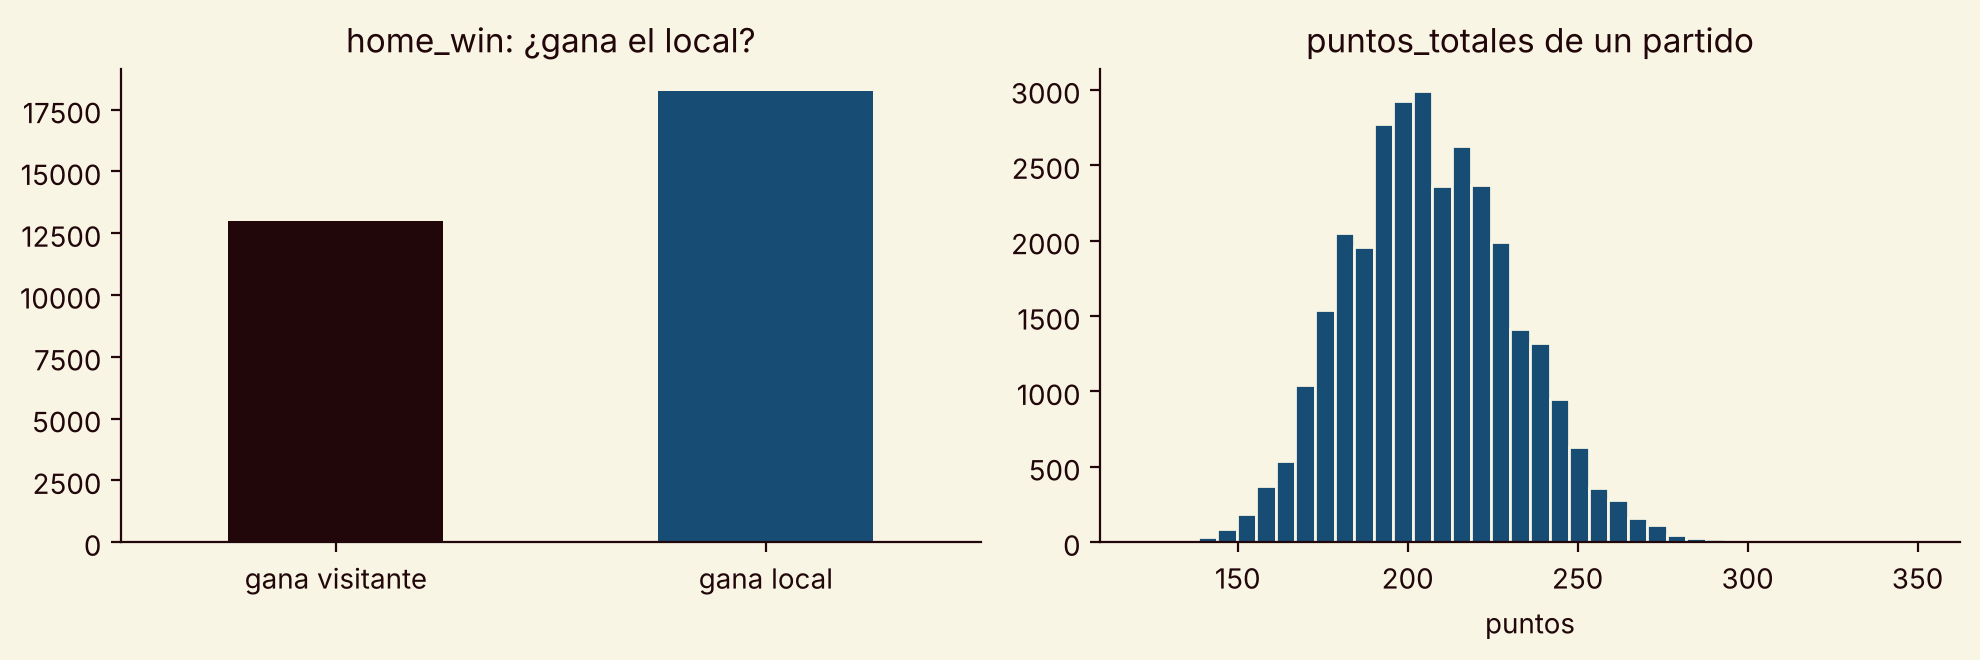

Porcentaje que gana el local: 58.4 % (la base de comparación: «gana siempre el local»)


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
final["home_win"].value_counts().sort_index().rename({0: "gana visitante", 1: "gana local"}).plot.bar(ax=ax[0], color=[GRANATE, AZUL], rot=0)
ax[0].set_title("home_win: ¿gana el local?"); ax[0].set_xlabel("")
ax[1].hist(final["puntos_totales"], bins=40, color=AZUL, edgecolor=CREMA)
ax[1].set_title("puntos_totales de un partido"); ax[1].set_xlabel("puntos")
plt.tight_layout(); plt.show()
print("Porcentaje que gana el local:", round(100 * final.home_win.mean(), 1), "% (la base de comparación: «gana siempre el local»)")

## 6. Entradas (X) y salidas (y)

- **Entradas (X)**: las columnas `local_…`, `visit_…` y `dif_…`. Todas describen **cómo llegaba cada equipo al partido**
  (puntos a favor y en contra, margen, % de victorias en los últimos 5/10 partidos, descanso, si juega el segundo día seguido,
  récord de la temporada) y, con `TeamStatistics`, tiros, rebotes y pérdidas.
- **Salidas (y)**: `home_win` (clasificación) y `puntos_totales` (regresión). Cada objetivo usa **su propia salida**
  con las mismas entradas (o un subconjunto).
- **Identificadores** (`gameId`, `fecha`, `temporada`, ids de equipo): sirven para ordenar y separar, **no** como entrada.
- **Fuera para siempre** (son el resultado o se saben al acabar): `homeScore`, `awayScore`, `winner`, `plusMinusPoints`,
  puntos por cuarto, `attendance`, `officials`, y cualquier estadística del propio partido.

## 7. Cómo separamos entrenamiento, prueba y segundo lote
Como el tiempo importa, **no mezclamos filas al azar**: entrenamos con lo antiguo y probamos con lo más reciente,
igual que pasaría en la vida real. Las fechas de abajo son un ejemplo orientativo.

| Trozo | Temporadas (ejemplo) | Para qué |
|---|---|---|
| Entrenamiento | 2000-01 a 2022-23 | Que el modelo aprenda |
| Prueba | 2023-24 | Medir cómo funciona con datos que no ha visto |
| **Lote 2** | 2024-25 en adelante | Simular que llegan datos nuevos y comprobar **drift** (si las cosas han cambiado) |

In [15]:
def trozo(t):
    return "1_entrenamiento" if t <= 2022 else ("2_prueba" if t == 2023 else "3_lote2_drift")
final = final.assign(trozo=final["temporada"].map(trozo))

resumen = final.groupby("trozo").agg(partidos=("gameId", "size"), desde=("fecha", "min"), hasta=("fecha", "max"),
                                     pct_gana_local=("home_win", "mean"), media_puntos_totales=("puntos_totales", "mean"))
resumen[["pct_gana_local", "media_puntos_totales"]] = resumen[["pct_gana_local", "media_puntos_totales"]].round(3)
resumen

,partidos,desde,hasta,pct_gana_local,media_puntos_totales
trozo,,,,,
1_entrenamiento,27402,2000-11-18,2023-04-09,0.589,203.708
2_prueba,1164,2023-10-24,2024-04-14,0.540,228.339
3_lote2_drift,2660,2024-10-22,2026-11-16,0.547,229.297


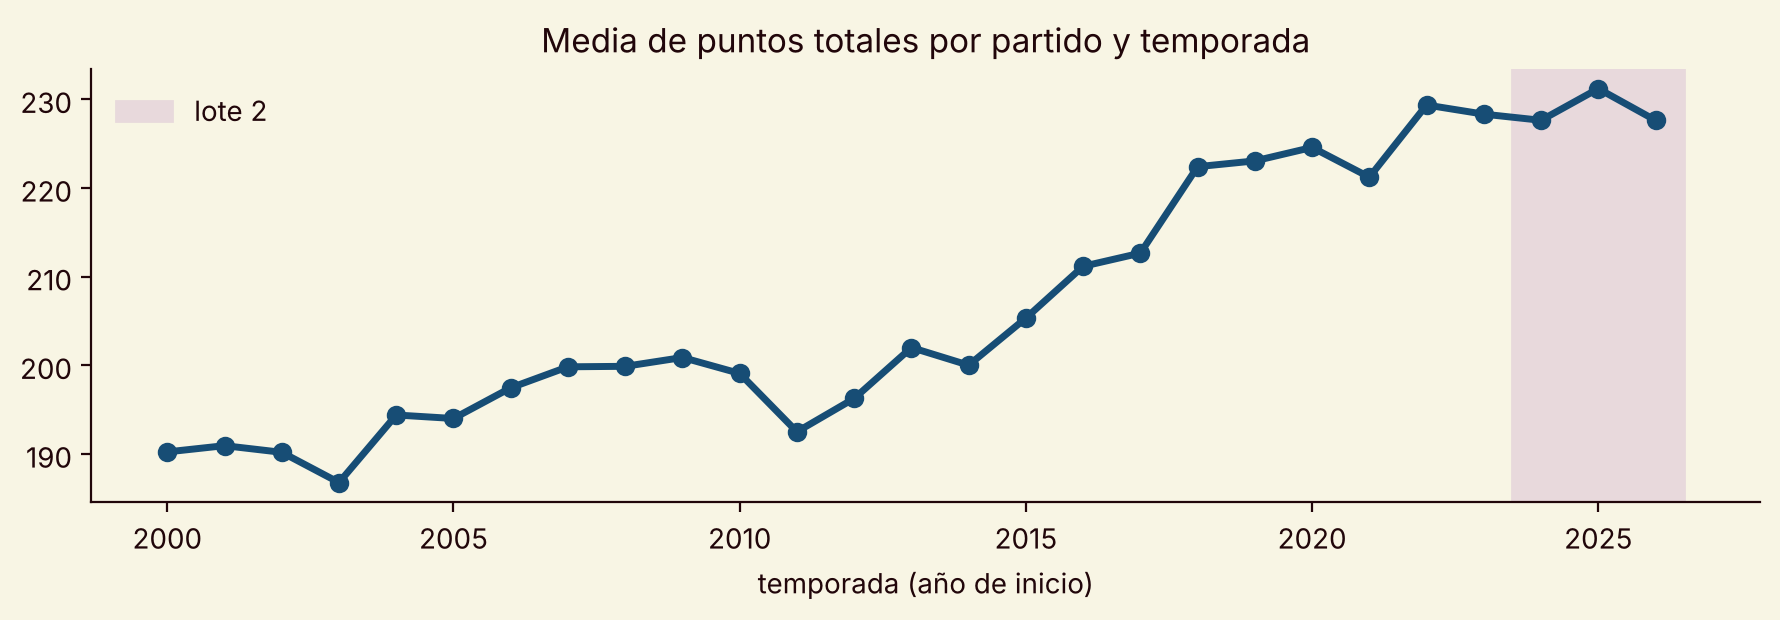

In [16]:
# Una pista de por qué hace falta vigilar el drift: los puntos totales por partido han cambiado mucho con los años
medias = final.groupby("temporada")["puntos_totales"].mean()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(medias.index, medias.values, color=AZUL, lw=2.5, marker="o")
ax.axvspan(2023.5, medias.index.max() + .5, color=GRANATE_CLARO, label="lote 2")
ax.set_title("Media de puntos totales por partido y temporada"); ax.set_xlabel("temporada (año de inicio)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 8. Resumen y siguiente paso

- El dataset de modelado es **una tabla con una fila por partido**: unas decenas de columnas de entrada, dos de salida
  y las de identificación.
- Las entradas son siempre **resúmenes de partidos anteriores** (con `shift(1)`), así que el modelo solo sabe lo que se sabía antes del partido.
- Se separa **por fechas**: entrenamiento antiguo, prueba reciente y un lote 2 para estudiar drift.
- **Qué modelo usar todavía no lo sabemos**: lo decidiremos comparando varios sobre esta misma tabla (siguiente fase).
- Sin datos de jugadores: solo equipo y partido.

In [17]:
# Para guardarlo (en local, NO en GitHub): formato Parquet, igual que en la capa «curada» de HDFS
# final.to_parquet("modelado_partidos.parquet", index=False)